In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

df = pd.read_csv("../penguins.csv")

df.head()

,id,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,species
0,1,Torgersen,39.1,18.7,181.0,3750.0,male,2007,Adelie
1,2,Torgersen,39.5,17.4,186.0,3800.0,female,2007,Adelie
2,3,Torgersen,40.3,18.0,195.0,3250.0,female,2007,Adelie
3,4,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,Adelie
4,5,Torgersen,36.7,19.3,193.0,3450.0,female,2007,Adelie


In [2]:
print("".center(50, '='))
print(f"Shape: {df.shape}")
print("".center(50, '='))
print(df.describe())
print("[ Null values ]".center(50, '='))
print(df.isna().sum())

Shape: (344, 9)
               id  bill_length_mm  bill_depth_mm  flipper_length_mm  \
count  344.000000      342.000000     342.000000         342.000000   
mean   172.500000       43.921930      17.151170         200.915205   
std     99.448479        5.459584       1.974793          14.061714   
min      1.000000       32.100000      13.100000         172.000000   
25%     86.750000       39.225000      15.600000         190.000000   
50%    172.500000       44.450000      17.300000         197.000000   
75%    258.250000       48.500000      18.700000         213.000000   
max    344.000000       59.600000      21.500000         231.000000   

       body_mass_g         year  
count   342.000000   344.000000  
mean   4201.754386  2008.029070  
std     801.954536     0.818356  
min    2700.000000  2007.000000  
25%    3550.000000  2007.000000  
50%    4050.000000  2008.000000  
75%    4750.000000  2009.000000  
max    6300.000000  2009.000000  
=================[ Null values ]======

## Variables numéricas

In [3]:
numeric_cols = df.select_dtypes(include=['number']).columns
numeric_cols

Index(['id', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'year'],
      dtype='str')

## Variables categóricas

In [4]:
cat_cols = df.select_dtypes(include=['object', 'str']).columns
cat_cols

Index(['island', 'sex', 'species'], dtype='str')

## Limpieza de datos numéricos

Limpieza de los datos en todas las columnas donde hagan falta valores usando el promedio

In [5]:
# Para evitar hacerlo una por una
# df['bill_length_mm'] = df['bill_length_mm'].mean()

for column in numeric_cols:
    df[column] = df[column].fillna(df[column].mean())

## Rellenando datos categóricos

In [6]:
for column in cat_cols:
    if df[column].isna().any():
        df[column] = df[column].fillna(df[column].mode()[0])

## Verificando los valores nulos

In [7]:
print("[ Null values ]".center(50, '='))
print(df.isna().sum())

=================[ Null values ]==================
id                   0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
species              0
dtype: int64


# Exploración del dataset

In [8]:
sns.set_theme(style='whitegrid', palette='viridis')

## Gráfica por especies

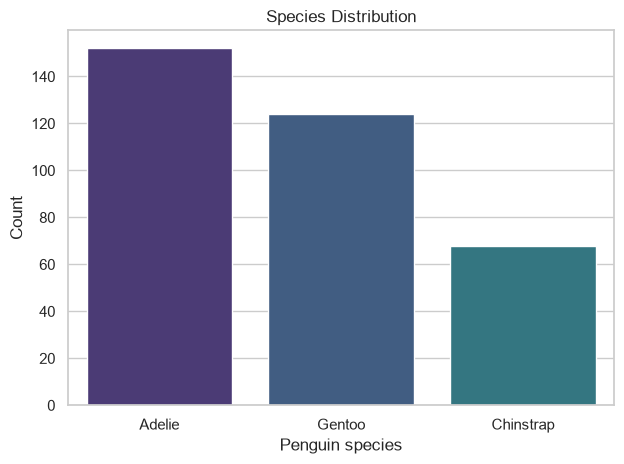

In [9]:
sns.countplot(data=df, x='species', hue='species')
plt.title('Species Distribution')
plt.xlabel('Penguin species')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Gráfica de correlación

Correlación entre longitud y anchura del pico entre pingüinos

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

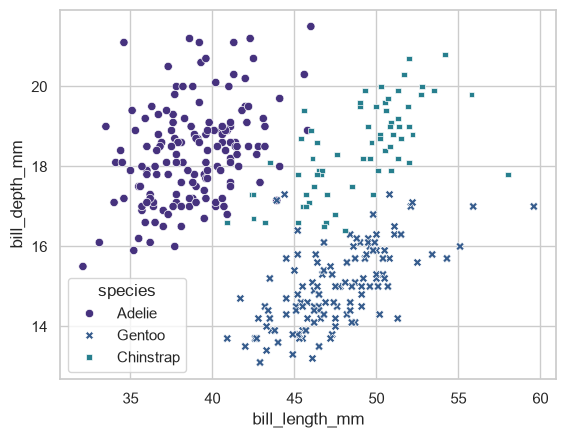

In [10]:
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species', style='species')

## Gráfica de masa corporal

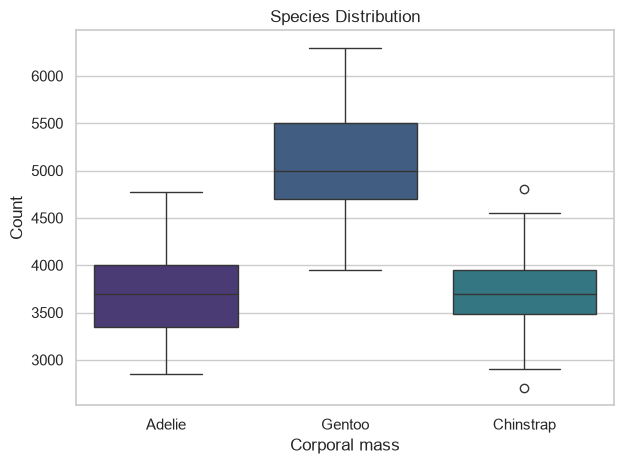

In [11]:
sns.boxplot(data=df, x='species', y='body_mass_g', hue='species')
plt.title('Species Distribution')
plt.xlabel('Corporal mass')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Separar datos en X y target

In [12]:
# Eliminado de la columna id
X = df.iloc[:, 1:7]
Y = df.iloc[:, -1]

## Ajuste de las variables categóricas

In [13]:
X = pd.get_dummies(X, dtype=int)
Y = pd.get_dummies(Y, dtype=int)

## Escalado de los datos

In [14]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [15]:
knn = KNeighborsClassifier()

parameters = {
    "n_neighbors": [5, 7, 10, 15, 20],
    "weights": ["uniform", "distance"],
    "metric": ["minkowski", "manhattan"]
}

grid = GridSearchCV(estimator=knn,
                    param_grid=parameters,
                    cv=10,
                    scoring='accuracy')

start = time.time()
grid.fit(X, Y)
end = time.time()

print(f"Best hyperparameters: {grid.best_params_}")
print(f"Best Accuracy: {grid.best_score_:.2f}%")
print(f"Best score: {grid.best_score_:.2f}")
print(f"Training time: {end - start:.2f} seconds")


Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Best Accuracy: 0.99%
Best score: 0.99
Training time: 1.02 seconds
